In [3]:


import pandas as pd

df = pd.read_csv("../data/retail_sales_dataset.csv")

df.head()



,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [5]:
df.shape



(1000, 9)

In [6]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    1000 non-null   int64 
 1   Date              1000 non-null   object
 2   Customer ID       1000 non-null   object
 3   Gender            1000 non-null   object
 4   Age               1000 non-null   int64 
 5   Product Category  1000 non-null   object
 6   Quantity          1000 non-null   int64 
 7   Price per Unit    1000 non-null   int64 
 8   Total Amount      1000 non-null   int64 
dtypes: int64(5), object(4)
memory usage: 70.4+ KB


In [7]:

df.columns

Index(['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age',
       'Product Category', 'Quantity', 'Price per Unit', 'Total Amount'],
      dtype='object')

In [1]:
## eda 

In [4]:
print("Total Revenue:", df["Total Amount"].sum())

print("Total Transactions:", df["Transaction ID"].nunique())

print("Total Customers:", df["Customer ID"].nunique())

print("Average Transaction Value:", df["Total Amount"].mean())

Total Revenue: 456000
Total Transactions: 1000
Total Customers: 1000
Average Transaction Value: 456.0


In [5]:
category_sales = (
    df.groupby("Product Category")["Total Amount"]
      .sum()
      .sort_values(ascending=False)
)

category_sales

Product Category
Electronics    156905
Clothing       155580
Beauty         143515
Name: Total Amount, dtype: int64

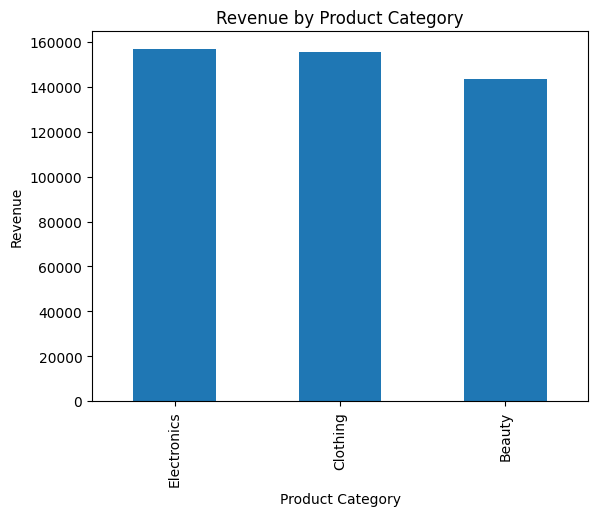

In [21]:
import matplotlib.pyplot as plt

category_sales.plot(kind="bar")

plt.title("Revenue by Product Category")
plt.ylabel("Revenue")

plt.savefig("../visuals/revenue_by_category.png")

plt.show()

In [22]:
import os

os.path.getsize("../visuals/revenue_by_category.png")

19032

### Product Category Insights

* Electronics generated the highest revenue (156,905), contributing approximately 34.4% of total sales.
* Clothing closely followed with revenue of 155,580, indicating comparable customer demand.
* Beauty generated the lowest revenue (143,515), contributing approximately 31.5% of total sales.
* Revenue distribution is relatively balanced across categories, reducing dependence on a single product segment.
* Increasing marketing efforts for Beauty products could help improve overall revenue growth.


In [7]:
gender_sales = df.groupby("Gender")["Total Amount"].sum()

print(gender_sales)

Gender
Female    232840
Male      223160
Name: Total Amount, dtype: int64


In [8]:
gender_avg = df.groupby("Gender")["Total Amount"].mean()

print(gender_avg)

Gender
Female    456.549020
Male      455.428571
Name: Total Amount, dtype: float64


### Gender Analysis Insights

* Female customers generated total revenue of 232,840, slightly higher than male customers at 223,160.
* Female customers contributed approximately 51% of total sales revenue.
* Average transaction values were nearly identical for both genders (456.55 for females and 455.43 for males).
* Customer spending behavior appears consistent across genders.
* Since purchasing patterns are similar, segmenting customers based on age or product preferences may be more effective than gender-based marketing strategies.


In [9]:
df["Age Group"] = pd.cut(
    df["Age"],
    bins=[0,20,30,40,50,100],
    labels=["<20","20-30","30-40","40-50","50+"]
)

age_sales = (
    df.groupby("Age Group")["Total Amount"]
      .sum()
      .sort_values(ascending=False)
)

print(age_sales)

Age Group
50+      133310
20-30     98215
30-40     95950
40-50     93795
<20       34730
Name: Total Amount, dtype: int64


C:\Users\mutth\AppData\Local\Temp\ipykernel_1860\830940898.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby("Age Group")["Total Amount"]


### Age Group Analysis Insights

* Customers aged 50 and above generated the highest revenue (133,310), making them the most valuable customer segment.
* Customers below 20 years contributed the least revenue (34,730), indicating lower purchasing activity.
* Revenue contributions from the 20–30, 30–40, and 40–50 age groups were relatively balanced.
* The business appears to have strong appeal among middle-aged and older customers.
* Marketing campaigns focused on customers aged 50+ may yield higher returns due to their stronger purchasing behavior.


In [10]:
df.groupby("Age Group")["Total Amount"].mean()

C:\Users\mutth\AppData\Local\Temp\ipykernel_1860\4041055372.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby("Age Group")["Total Amount"].mean()


Age Group
<20      551.269841
20-30    467.690476
30-40    497.150259
40-50    424.411765
50+      425.910543
Name: Total Amount, dtype: float64

### Average Transaction Value by Age Group

* Customers below 20 years recorded the highest average transaction value (551.27).
* Customers aged 50+ generated the highest total revenue but had a lower average transaction value (425.91).
* This suggests that revenue from the 50+ segment is driven by transaction frequency, while younger customers tend to make larger purchases when they buy.
* Different age groups exhibit distinct purchasing behaviors, which can help guide targeted marketing strategies.


In [15]:
df["Date"] = pd.to_datetime(df["Date"])

In [16]:
df["Month"] = df["Date"].dt.month_name()

monthly_sales = (
    df.groupby("Month")["Total Amount"]
      .sum()
)

print(monthly_sales)

Month
April        33870
August       36960
December     44690
February     44060
January      36980
July         35465
June         36715
March        28990
May          53150
November     34920
October      46580
September    23620
Name: Total Amount, dtype: int64


In [13]:
df.columns

Index(['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age',
       'Product Category', 'Quantity', 'Price per Unit', 'Total Amount',
       'Age Group'],
      dtype='object')

In [17]:
df.groupby("Product Category")["Quantity"].sum()

Product Category
Beauty         771
Clothing       894
Electronics    849
Name: Quantity, dtype: int64

### Product Quantity Analysis Insights

* Clothing recorded the highest sales volume with 894 units sold.
* Electronics sold fewer units (849) but generated the highest revenue (156,905).
* This indicates that Electronics products have a higher average selling price compared to Clothing products.
* Beauty products ranked lowest in both revenue and quantity sold.
* Revenue performance is influenced not only by sales volume but also by product pricing.


In [18]:
pd.pivot_table(
    df,
    values="Total Amount",
    index="Gender",
    columns="Product Category",
    aggfunc="sum"
)

Product Category,Beauty,Clothing,Electronics
Gender,,,
Female,74830,81275,76735
Male,68685,74305,80170


In [19]:
df[["Age", "Total Amount"]].corr()

,Age,Total Amount
Age,1.000000,-0.060568
Total Amount,-0.060568,1.000000


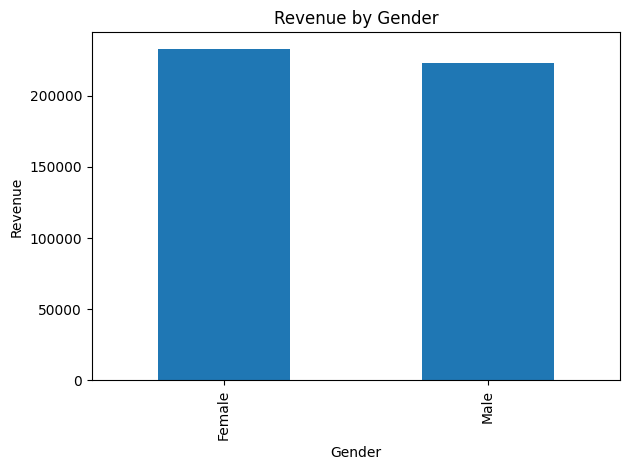

In [24]:
gender_sales = df.groupby("Gender")["Total Amount"].sum()
import matplotlib.pyplot as plt

gender_sales.plot(kind="bar")

plt.title("Revenue by Gender")
plt.xlabel("Gender")
plt.ylabel("Revenue")

plt.tight_layout()

plt.savefig(
    "../visuals/revenue_by_gender.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

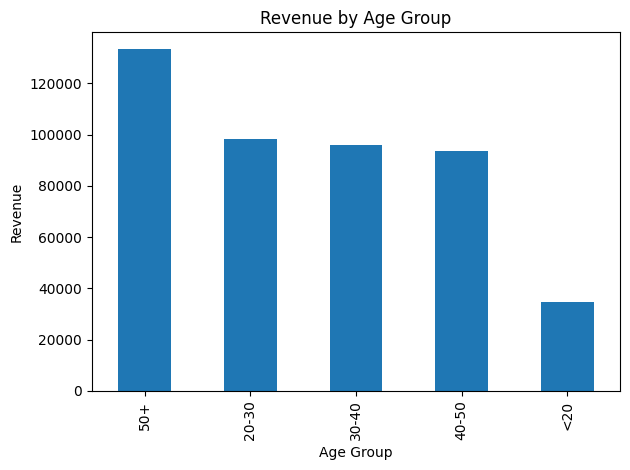

In [25]:
import matplotlib.pyplot as plt

age_sales.plot(kind="bar")

plt.title("Revenue by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Revenue")

plt.tight_layout()

plt.savefig(
    "../visuals/revenue_by_age_group.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

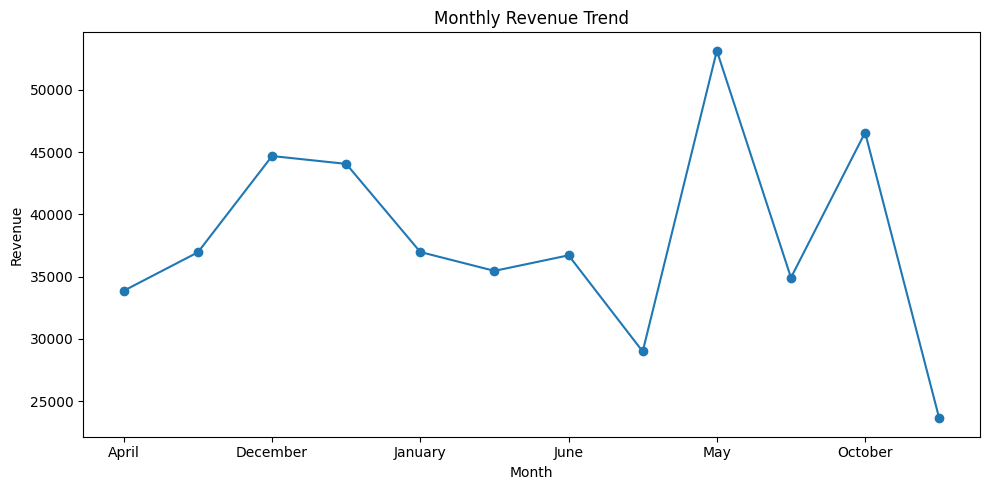

In [26]:
import matplotlib.pyplot as plt

monthly_sales.plot(
    kind="line",
    marker="o",
    figsize=(10,5)
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")

plt.tight_layout()

plt.savefig(
    "../visuals/monthly_revenue_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()